Text(0.5, 1.0, 'Оригинал с периодическим шумом')

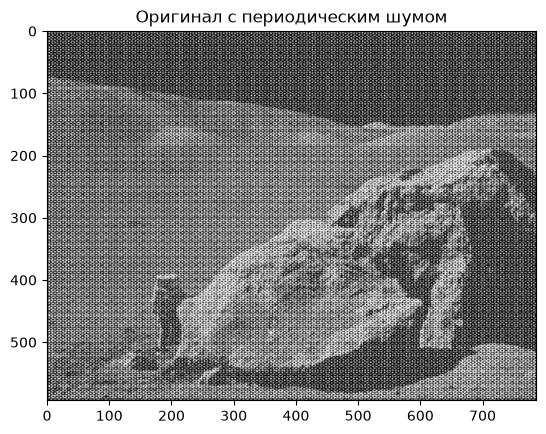

In [1]:
import numpy as np
import math
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('periodic_noise.JPG', cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')
plt.title('Оригинал с периодическим шумом')

Text(0.5, 1.0, 'Результат High-pass')

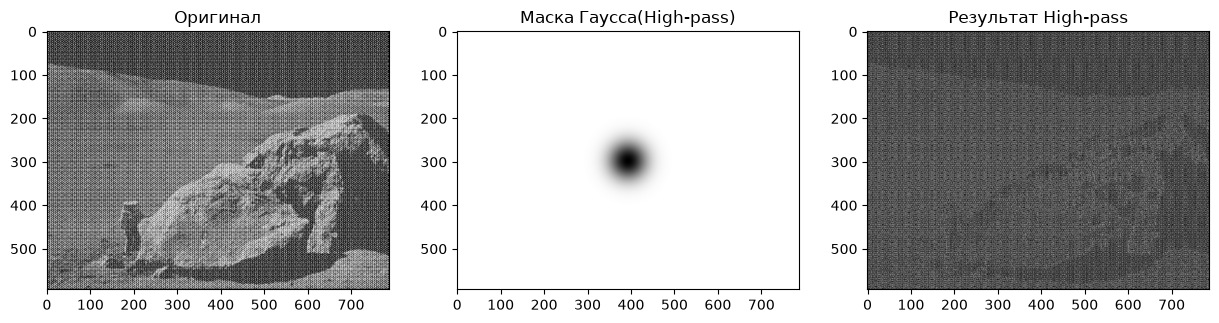

In [4]:
# реализация высокочастотной фильтрации на основе ядра Гаусса
# 1. Прямое Дискретное Преобразование Фурье(ДПФ, берет картинку и превращает в спектр)  и сдвиг(в центр)
dft = cv2.dft(np.float32(img), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

# 2. Создаем маску Гаусса (High-pass)
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

# квадрат расстояния от центра спектра
u = np.arange(rows) - crow
v = np.arange(cols) - ccol
U, V = np.meshgrid(v, u)
D2 = U**2 + V**2

sigma = 30
gaussian_lowpass = np.exp(-D2 / (2 * sigma**2))
high_pass_mask = 1 - gaussian_lowpass

# применение маски
high_pass_mask_3d = np.dstack([high_pass_mask, high_pass_mask])
dft_shift_filtered = dft_shift * high_pass_mask_3d

# обратное ДПФ - преобразование отфильтрованного спектра обратно в пиксели
f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_back = cv2.idft(f_ishift)
img_highpass = cv2.magnitude(img_back[:,:,0], img_back[:,:,1])

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 3, 2)
plt.imshow(high_pass_mask, cmap='gray')
plt.title('Маска Гаусса(High-pass)')

plt.subplot(1, 3, 3)
plt.imshow(img_highpass, cmap='gray')
plt.title('Результат High-pass')

Text(0.5, 1.0, 'Свертка в пространстве(как проверка)')

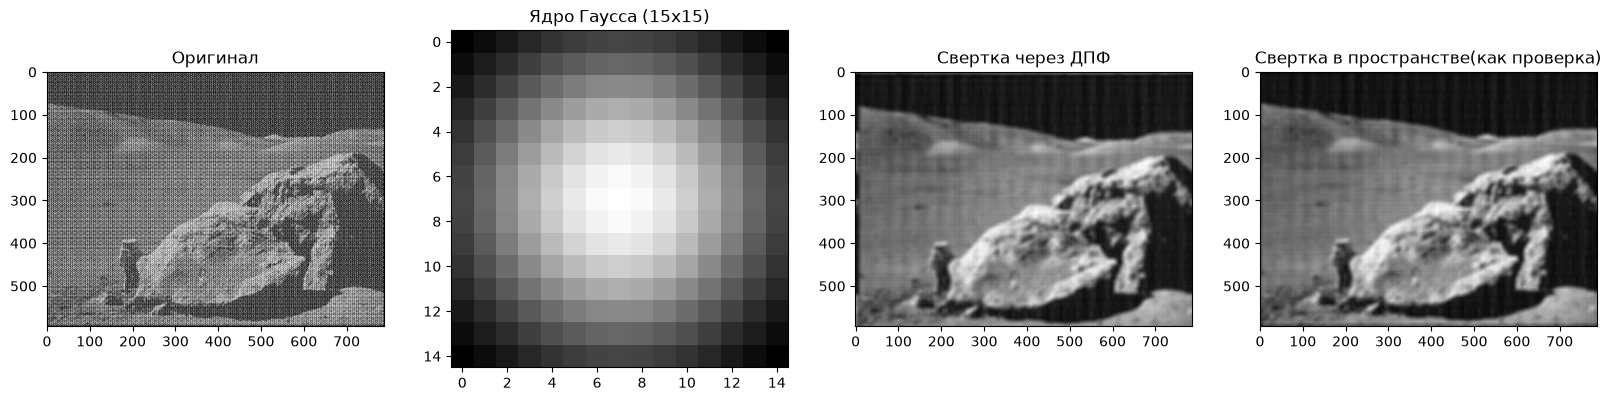

In [7]:
# создание ядра Гаусса в пространственной области(фильтр низких частот)
kernel_size = 15
sigma_kernel = 5
kernel_1d = cv2.getGaussianKernel(kernel_size, sigma_kernel)
kernel_2d = np.outer(kernel_1d, kernel_1d)

# дополнение ядра нулями до размера изображения
kernel_padded = np.zeros_like(img, dtype=np.float32)
kernel_padded[:kernel_size, :kernel_size] = kernel_2d

# вычисление прямого ДПФ для картинки и для ядра
dft_img = cv2.dft(np.float32(img), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_kernel = cv2.dft(kernel_padded, flags=cv2.DFT_COMPLEX_OUTPUT)

# свертка в частотной области(перемножение спектров)
dft_conv = cv2.mulSpectrums(dft_img, dft_kernel, 0)

# обратное ДПФ
img_back_conv = cv2.idft(dft_conv)
img_conv_ft = cv2.magnitude(img_back_conv[:,:,0], img_back_conv[:,:,1])

# для сравнения та же свертка в пространственной области
img_conv_spatial = cv2.filter2D(img, -1, kernel_2d)

plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 4, 2)
plt.imshow(kernel_2d, cmap='gray')
plt.title('Ядро Гаусса (15x15)')

plt.subplot(1, 4, 3)
plt.imshow(img_conv_ft, cmap='gray')
plt.title('Свертка через ДПФ')

plt.subplot(1, 4, 4)
plt.imshow(img_conv_spatial, cmap='gray')
plt.title('Свертка в пространстве(как проверка)')

Text(0.5, 1.0, 'Результат')

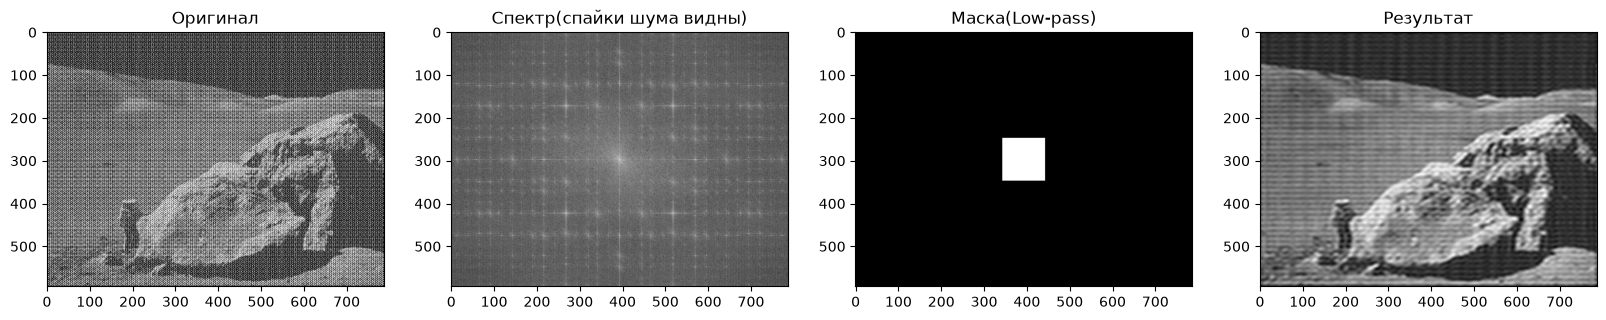

In [10]:
# реализация удаления периодического шума с помощью преобразования Фурье
# прямое ДПФ и сдвиг
dft = cv2.dft(np.float32(img), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

# магнитуда спектра для визуализации
magnitude_spectrum = 20 * np.log(cv2.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]))

# создание маски(Low-pass)
mask = np.zeros((img.shape[0], img.shape[1], 2), np.uint8)
centerX, centerY = (int(img.shape[0] / 2), int(img.shape[1] / 2))
# только центр
mask[centerX-50:centerX+50, centerY-50:centerY+50, :] = 1

# фильтрация(спектра * маска)
dft_shift_filtered = dft_shift * mask

# обратное ДПФ
f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_back = cv2.idft(f_ishift)
img_filtered = cv2.magnitude(img_back[:,:,0], img_back[:,:,1])

plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 4, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Спектр(спайки шума видны)')

plt.subplot(1, 4, 3)
plt.imshow(mask[:,:,0], cmap='gray')
plt.title('Маска(Low-pass)')

plt.subplot(1, 4, 4)
plt.imshow(img_filtered, cmap='gray')
plt.title('Результат')